## Tugas Praktikum 5: Sequential Pattern Analysis

|     NRP      |     Nama       |
|-----------   |-------------   |
| 5054251013   | Evina Fitriyani| 

## 1. Import Dataset

Dataset yang dipakai Online Retail dari UCI Machine Learning Repository, berisi transaksi ritel online di Inggris dari Desember 2010 sampai Desember 2011 (541.909 baris, 8 kolom). Untuk tugas ini kolom CustomerID dan InvoiceDate dipakai buat nyusun urutan pembelian tiap pelanggan.

Data set: https://archive.ics.uci.edu/dataset/352/online+retail


In [3]:
# import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from prefixspan import PrefixSpan

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

In [4]:
# import dataset Online Retail.xlsx

df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print(df.shape)

(541909, 8)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 2. Eksplorasi dan Pembersihan Data

### 2.1 Eksplorasi Data

Kolom yang relevan buat Sequential Pattern ada tiga: CustomerID (pemilik sequence), InvoiceDate (urutan waktu), dan Description (nama produk). InvoiceNo dipakai buat nandain item mana yang dibeli di invoice yang sama.


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [9]:
# simpan jumlah baris, invoice, dan pelanggan sebelum dibersihkan

baris_awal = df.shape[0]
invoice_awal = df['InvoiceNo'].nunique()
pelanggan_awal = df['CustomerID'].nunique()

print('Sebelum cleaning')
print('Jumlah baris     :', baris_awal)
print('Jumlah invoice   :', invoice_awal)
print('Jumlah pelanggan :', pelanggan_awal)

Sebelum cleaning
Jumlah baris     : 541909
Jumlah invoice   : 25900
Jumlah pelanggan : 4372


### 2.2 Pembersihan Data

Tahap pembersihan yang dilakukan:
- Hapus baris yang Description-nya kosong
- Hapus baris yang CustomerID-nya kosong, karena sequence disusun per pelanggan
- Hapus transaksi yang dibatalkan (InvoiceNo diawali huruf "C")
- Hapus baris dengan Quantity negatif atau nol
- Hapus baris yang bukan produk beneran (POSTAGE, Manual, dll)


In [10]:
# hapus Description kosong dan CustomerID kosong

df_clean = df.dropna(subset=['Description', 'CustomerID']).copy()
print('Shape setelah buang data kosong:', df_clean.shape)

Shape setelah buang data kosong: (406829, 8)


In [11]:
# hapus invoice batal (awalan C) dan Quantity <= 0

df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]
print('Shape setelah buang invoice batal dan Quantity <= 0:', df_clean.shape)

Shape setelah buang invoice batal dan Quantity <= 0: (397924, 8)


In [12]:
# rapikan spasi di nama produk, lalu buang baris yang bukan produk

df_clean['Description'] = df_clean['Description'].str.strip()

bukan_produk = ['POSTAGE', 'Manual', 'DOTCOM POSTAGE', 'CARRIAGE', 'Discount', 'SAMPLES', 'AMAZON FEE', 'Bank Charges']
df_clean = df_clean[~df_clean['Description'].isin(bukan_produk)]
print('Shape setelah buang non-produk:', df_clean.shape)

Shape setelah buang non-produk: (396374, 8)


In [13]:
# perbandingan jumlah baris, invoice, dan pelanggan sebelum dan sesudah cleaning

print('Sesudah cleaning')
print('Jumlah baris     :', df_clean.shape[0])
print('Jumlah invoice   :', df_clean['InvoiceNo'].nunique())
print('Jumlah pelanggan :', df_clean['CustomerID'].nunique())
print('Jumlah produk    :', df_clean['Description'].nunique())

hasil = pd.DataFrame({
    'Tahap': ['Sebelum', 'Sesudah'],
    'Jumlah Baris': [baris_awal, df_clean.shape[0]],
    'Jumlah Invoice': [invoice_awal, df_clean['InvoiceNo'].nunique()],
    'Jumlah Pelanggan': [pelanggan_awal, df_clean['CustomerID'].nunique()]
})
hasil

Sesudah cleaning
Jumlah baris     : 396374
Jumlah invoice   : 18405
Jumlah pelanggan : 4335
Jumlah produk    : 3861


,Tahap,Jumlah Baris,Jumlah Invoice,Jumlah Pelanggan
0,Sebelum,541909,25900,4372
1,Sesudah,396374,18405,4335


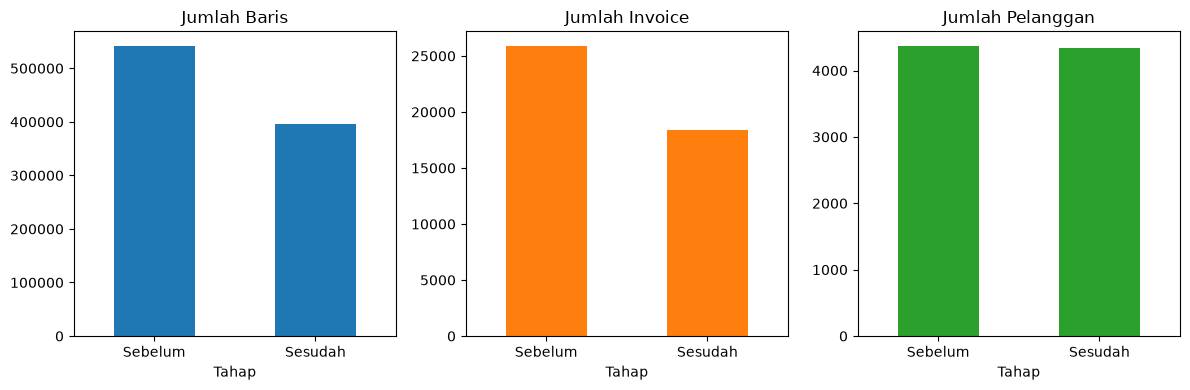

In [14]:
# visualisasi perbandingan sebelum dan sesudah cleaning

hasil.set_index('Tahap').plot(kind='bar', subplots=True, layout=(1, 3), figsize=(12, 4), legend=False, rot=0)
plt.tight_layout()
plt.show()

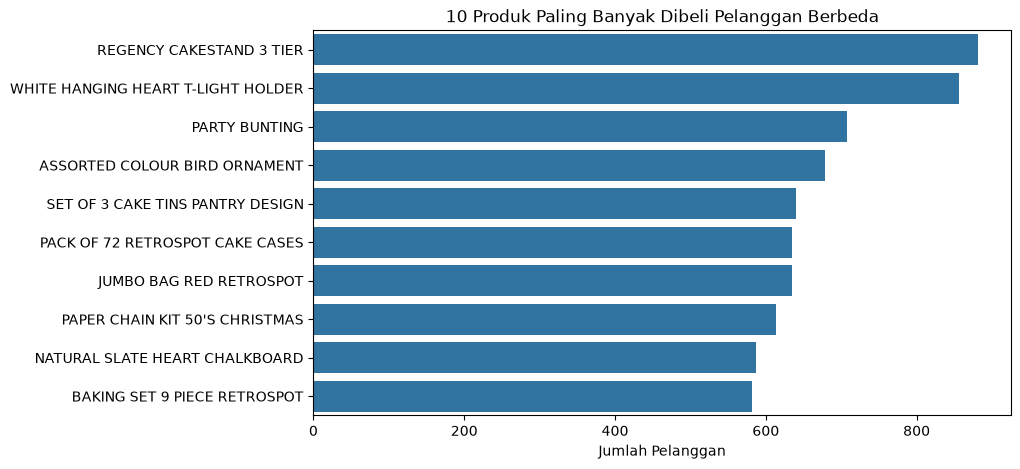

In [15]:
# 10 produk yang paling banyak dibeli pelanggan berbeda

top_produk = df_clean.groupby('Description')['CustomerID'].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(9,5))
sns.barplot(x=top_produk.values, y=top_produk.index)
plt.title('10 Produk Paling Banyak Dibeli Pelanggan Berbeda')
plt.xlabel('Jumlah Pelanggan')
plt.ylabel('')
plt.show()

count    4335.000000
mean        4.245675
std         7.636337
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       206.000000
Name: InvoiceNo, dtype: float64


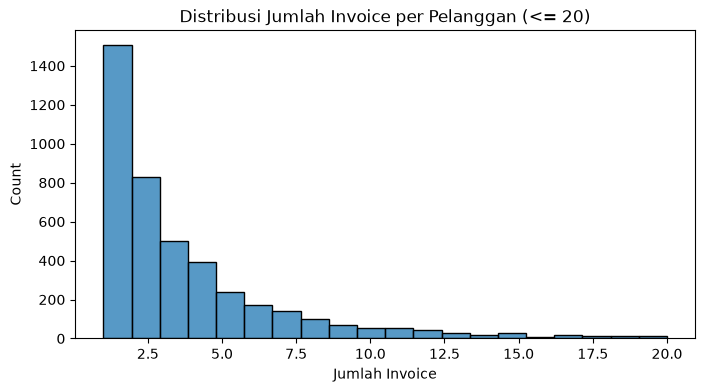

In [16]:
# distribusi jumlah invoice per pelanggan (ini yang jadi panjang urutan beli)

invoice_per_pelanggan = df_clean.groupby('CustomerID')['InvoiceNo'].nunique()
print(invoice_per_pelanggan.describe())

plt.figure(figsize=(8,4))
sns.histplot(invoice_per_pelanggan[invoice_per_pelanggan <= 20], bins=20)
plt.title('Distribusi Jumlah Invoice per Pelanggan (<= 20)')
plt.xlabel('Jumlah Invoice')
plt.show()

## 3. Persiapan Data untuk Sequential Pattern Mining

### 3.1 Urutan Waktu dan Itemset per Invoice

Data diurutkan berdasarkan CustomerID dan InvoiceDate. Item yang dibeli di invoice yang sama dijadikan satu itemset.


In [17]:
# urutkan data per pelanggan dan waktu

df_clean = df_clean.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'])
df_clean[['CustomerID', 'InvoiceNo', 'InvoiceDate', 'Description']].head(10)

,CustomerID,InvoiceNo,InvoiceDate,Description
61619,12346.0,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR
14938,12347.0,537626,2010-12-07 14:57:00,BLACK CANDELABRA T-LIGHT HOLDER
14939,12347.0,537626,2010-12-07 14:57:00,AIRLINE BAG VINTAGE JET SET BROWN
14940,12347.0,537626,2010-12-07 14:57:00,COLOUR GLASS. STAR T-LIGHT HOLDER
14941,12347.0,537626,2010-12-07 14:57:00,MINI PAINT SET VINTAGE
14942,12347.0,537626,2010-12-07 14:57:00,CLEAR DRAWER KNOB ACRYLIC EDWARDIAN
14943,12347.0,537626,2010-12-07 14:57:00,PINK DRAWER KNOB ACRYLIC EDWARDIAN
14944,12347.0,537626,2010-12-07 14:57:00,GREEN DRAWER KNOB ACRYLIC EDWARDIAN
14945,12347.0,537626,2010-12-07 14:57:00,RED DRAWER KNOB ACRYLIC EDWARDIAN
14946,12347.0,537626,2010-12-07 14:57:00,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN


In [18]:
# gabungkan item satu invoice jadi satu itemset

itemset_invoice = df_clean.groupby(['CustomerID', 'InvoiceNo', 'InvoiceDate'])['Description'].apply(lambda x: sorted(set(x))).reset_index()
itemset_invoice = itemset_invoice.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo']).reset_index(drop=True)

print('Jumlah itemset (invoice):', itemset_invoice.shape[0])
itemset_invoice.head()

Jumlah itemset (invoice): 18435


,CustomerID,InvoiceNo,InvoiceDate,Description
0,12346.0,541431,2011-01-18 10:01:00,[MEDIUM CERAMIC TOP STORAGE JAR]
1,12347.0,537626,2010-12-07 14:57:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOLATE..."
2,12347.0,542237,2011-01-26 14:30:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, AIRL..."
3,12347.0,549222,2011-04-07 10:43:00,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STICKERS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE ..."
4,12347.0,556201,2011-06-09 13:01:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE TOKYO 78, ..."


### 3.2 Sequence per Pelanggan

Tiap pelanggan dijadikan satu sequence, yaitu daftar produk yang dibeli berurutan dari invoice paling lama sampai paling baru. Library prefixspan cuma baca urutan item, jadi item dalam satu invoice ditulis berdampingan sesuai urutan invoicenya. Produk yang sama cuma dihitung sekali per pelanggan (pembelian pertamanya), supaya yang dicari urutan beli antar produk yang beda, bukan beli ulang.


In [19]:
# susun sequence tiap pelanggan (list of list)

sequences = []
for cust, grup in itemset_invoice.groupby('CustomerID'):
    seq = []
    sudah = set()
    for items in grup['Description']:
        for item in items:
            if item not in sudah:
                seq.append(item)
                sudah.add(item)
    sequences.append(seq)

print('Jumlah sequence (pelanggan):', len(sequences))
print(sequences[0][:10])

Jumlah sequence (pelanggan): 4335
['MEDIUM CERAMIC TOP STORAGE JAR']


In [20]:
# panjang sequence tiap pelanggan

panjang_seq = pd.Series([len(s) for s in sequences])
print(panjang_seq.describe())

count    4335.000000
mean       61.729873
std        86.097929
min         1.000000
25%        16.000000
50%        35.000000
75%        78.000000
max      1813.000000
dtype: float64


## 4. Penerapan Algoritma

### 4.1 PrefixSpan

Algoritma yang dipakai PrefixSpan dengan minimum support 0.01 (relatif terhadap jumlah pelanggan) sebagai titik awal. Panjang pola dibatasi maksimal 3 produk supaya prosesnya nggak kelamaan.


In [21]:
# jalankan PrefixSpan dengan min support 0.01

jumlah_pelanggan = len(sequences)
min_support = 0.01
min_count = int(np.ceil(min_support * jumlah_pelanggan))
print('Jumlah pelanggan:', jumlah_pelanggan)
print('Minimum jumlah pelanggan:', min_count)

ps = PrefixSpan(sequences)
ps.maxlen = 3
hasil_ps = ps.frequent(min_count)

print('Jumlah pola berurutan:', len(hasil_ps))

Jumlah pelanggan: 4335
Minimum jumlah pelanggan: 44
Jumlah pola berurutan: 19405


In [22]:
# ubah hasil ke dataframe

pola = pd.DataFrame(hasil_ps, columns=['jumlah_pelanggan', 'pola'])
pola['pola'] = pola['pola'].apply(tuple)
pola['panjang'] = pola['pola'].apply(len)
pola['support'] = pola['jumlah_pelanggan'] / jumlah_pelanggan

print(pola['panjang'].value_counts().sort_index())
pola.sort_values('support', ascending=False).head(10)

panjang
1     1761
2    13503
3     4141
Name: count, dtype: int64


,jumlah_pelanggan,pola,panjang,support
814,881,"(REGENCY CAKESTAND 3 TIER,)",1,0.203230
13348,856,"(WHITE HANGING HEART T-LIGHT HOLDER,)",1,0.197463
8145,708,"(PARTY BUNTING,)",1,0.163322
12545,678,"(ASSORTED COLOUR BIRD ORNAMENT,)",1,0.156401
3137,640,"(SET OF 3 CAKE TINS PANTRY DESIGN,)",1,0.147636
6266,635,"(PACK OF 72 RETROSPOT CAKE CASES,)",1,0.146482
9527,635,"(JUMBO BAG RED RETROSPOT,)",1,0.146482
15901,613,"(PAPER CHAIN KIT 50'S CHRISTMAS,)",1,0.141407
16317,587,"(NATURAL SLATE HEART CHALKBOARD,)",1,0.135409
4007,581,"(BAKING SET 9 PIECE RETROSPOT,)",1,0.134025


### 4.2 Penyesuaian Nilai Minimum Support

Kalau pola yang dihasilkan terlalu sedikit atau terlalu banyak, nilai support disesuaikan. Karena pola di support yang lebih tinggi pasti ada di hasil support 0.01, jumlah pola buat tiap nilai support bisa dihitung langsung dari tabel tadi.


In [23]:
# jumlah pola untuk beberapa nilai min support

for sup in [0.01, 0.02, 0.03, 0.05]:
    p = pola[pola['support'] >= sup]
    print(f"support >= {sup} -> {p.shape[0]} pola, {p[p['panjang'] >= 2].shape[0]} pola dengan panjang >= 2")

support >= 0.01 -> 19405 pola, 17644 pola dengan panjang >= 2
support >= 0.02 -> 2606 pola, 1562 pola dengan panjang >= 2
support >= 0.03 -> 958 pola, 303 pola dengan panjang >= 2
support >= 0.05 -> 291 pola, 27 pola dengan panjang >= 2


## 5. Evaluasi Pola Berurutan

### 5.1 Support dan Confidence

Support = persentase pelanggan yang punya pola itu di urutan belinya. Confidence dihitung dari pola panjang 2 ke atas: support seluruh pola dibagi support pola tanpa item terakhirnya, artinya dari pelanggan yang sudah beli urutan awalnya, berapa persen yang setelah itu beli item terakhir.


In [24]:
# hitung confidence tiap pola (panjang >= 2)

dict_count = dict(zip(pola['pola'], pola['jumlah_pelanggan']))

baris = []
for p, c in dict_count.items():
    if len(p) >= 2:
        awal = p[:-1]
        conf = c / dict_count[awal]
        baris.append({
            'pola_berurutan': ' -> '.join(p),
            'beli_dulu': ' -> '.join(awal),
            'lalu_beli': p[-1],
            'panjang': len(p),
            'jumlah_pelanggan': c,
            'support': c / jumlah_pelanggan,
            'confidence': conf
        })

hasil_pola = pd.DataFrame(baris).sort_values('support', ascending=False).reset_index(drop=True)
print('Jumlah pola panjang >= 2:', hasil_pola.shape[0])
hasil_pola[['beli_dulu', 'lalu_beli', 'jumlah_pelanggan', 'support', 'confidence']].head(20)

Jumlah pola panjang >= 2: 17644


,beli_dulu,lalu_beli,jumlah_pelanggan,support,confidence
0,PAPER CHAIN KIT 50'S CHRISTMAS,PAPER CHAIN KIT VINTAGE CHRISTMAS,301,0.069435,0.491028
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,297,0.068512,0.767442
2,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,290,0.066897,0.749354
3,REGENCY CAKESTAND 3 TIER,SET OF 3 REGENCY CAKE TINS,281,0.064821,0.318956
4,REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,279,0.064360,0.316686
5,HEART OF WICKER LARGE,HEART OF WICKER SMALL,272,0.062745,0.560825
6,PARTY BUNTING,SPOTTY BUNTING,265,0.061130,0.374294
7,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,243,0.056055,0.692308
8,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,242,0.055825,0.705539
9,LUNCH BAG RED RETROSPOT,LUNCH BAG SPACEBOY DESIGN,241,0.055594,0.453008


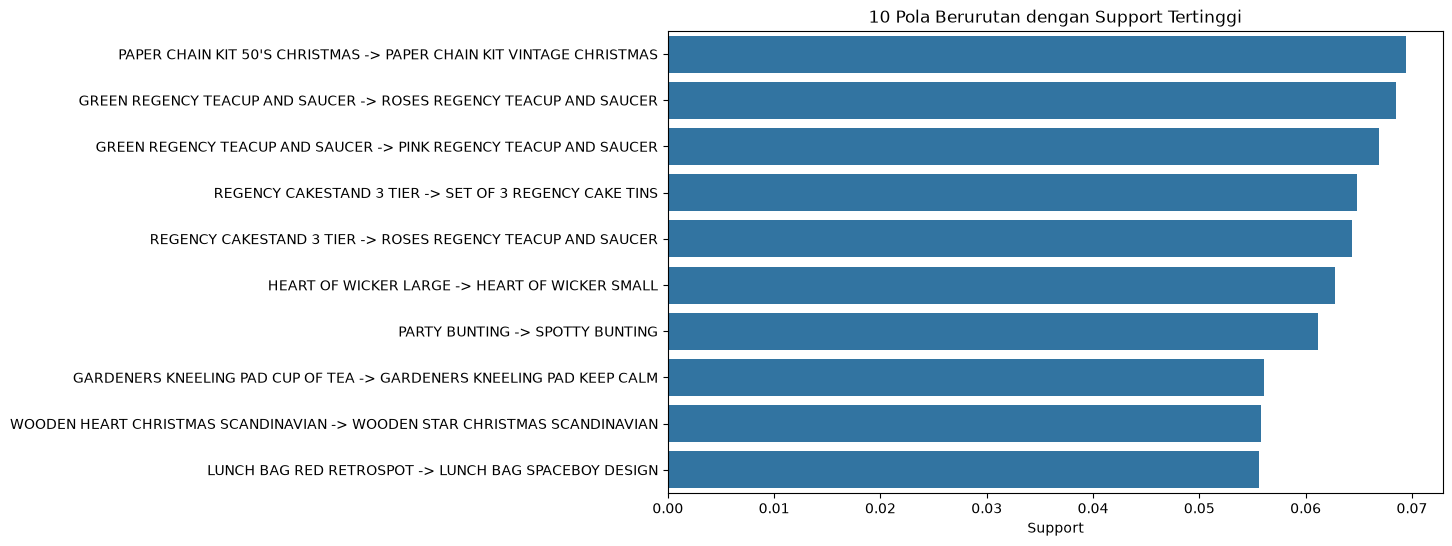

In [25]:
# visualisasi 10 pola dengan support tertinggi

top10 = hasil_pola.head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top10['support'], y=top10['pola_berurutan'])
plt.title('10 Pola Berurutan dengan Support Tertinggi')
plt.xlabel('Support')
plt.ylabel('')
plt.show()

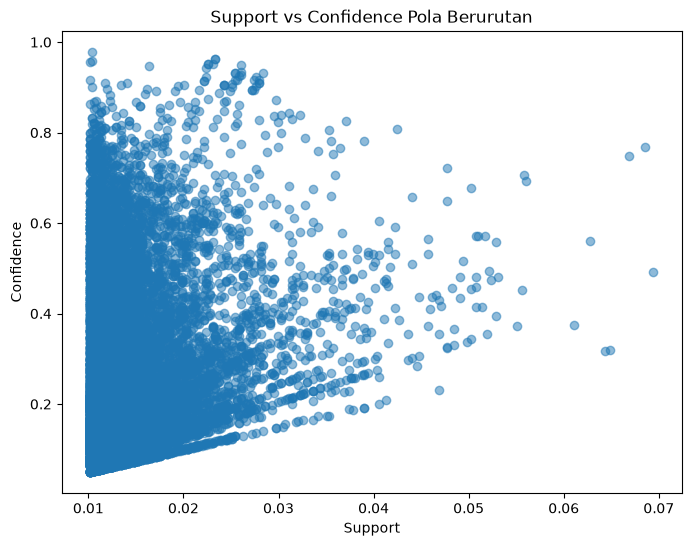

In [26]:
# visualisasi support vs confidence semua pola

plt.figure(figsize=(8,6))
plt.scatter(hasil_pola['support'], hasil_pola['confidence'], alpha=0.5)
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Support vs Confidence Pola Berurutan')
plt.show()

### 5.2 Tiga Pola Terbaik Berdasarkan Support

Tiga pola dengan support tertinggi, diambil dari pola yang panjangnya minimal 2 produk (kalau 1 produk bukan pola berurutan).


In [27]:
# pilih 3 pola dengan support tertinggi

top3 = hasil_pola.head(3)

for i, (_, r) in enumerate(top3.iterrows(), 1):
    print('Pola', i)
    print('  Urutan beli      :', r['pola_berurutan'])
    print('  Jumlah pelanggan :', r['jumlah_pelanggan'])
    print(f"  Support          : {r['support']:.4f}")
    print(f"  Confidence       : {r['confidence']:.4f}")
    print()

Pola 1
  Urutan beli      : PAPER CHAIN KIT 50'S CHRISTMAS -> PAPER CHAIN KIT VINTAGE CHRISTMAS
  Jumlah pelanggan : 301
  Support          : 0.0694
  Confidence       : 0.4910

Pola 2
  Urutan beli      : GREEN REGENCY TEACUP AND SAUCER -> ROSES REGENCY TEACUP AND SAUCER
  Jumlah pelanggan : 297
  Support          : 0.0685
  Confidence       : 0.7674

Pola 3
  Urutan beli      : GREEN REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER
  Jumlah pelanggan : 290
  Support          : 0.0669
  Confidence       : 0.7494



In [28]:
# tabel top 3 pola buat laporan

top3[['beli_dulu', 'lalu_beli', 'jumlah_pelanggan', 'support', 'confidence']]

,beli_dulu,lalu_beli,jumlah_pelanggan,support,confidence
0,PAPER CHAIN KIT 50'S CHRISTMAS,PAPER CHAIN KIT VINTAGE CHRISTMAS,301,0.069435,0.491028
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,297,0.068512,0.767442
2,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,290,0.066897,0.749354


### Ringkasan
- Dataset awal: 541909 baris, 8 kolom
- Baris dengan Description kosong, CustomerID kosong, invoice batal (awalan C), Quantity <= 0, dan non-produk dibuang
- Data diurutkan per CustomerID dan InvoiceDate, lalu tiap pelanggan dijadikan satu sequence pembelian
- Algoritma PrefixSpan dengan min support 0.01 (relatif terhadap jumlah pelanggan), panjang pola maksimal 3
- (isi sisanya setelah output keluar)